# 05 · Health checks and segments

**Question.** Besides the lift, the live page watches three things at every update: is the 50/50 split working, are the two groups alike, and is any group of players being harmed? Each is checked continuously, so each needs the same care as the verdict: no crying wolf from looking often.

**Milestone.** M9 · **Theory notes:** [anytime-valid](../docs/theory/anytime-valid.md), [balancing](../docs/theory/balancing.md), [hte](../docs/theory/hte.md)

## Where we are

The verdict uses the always-valid interval (notebook 03). Here we build the three checks that sit in the page's details:

1. **Is the split fair?** A sample-ratio mismatch (SRM) test. A broken split is the most common reason an online experiment's result is wrong, and it usually comes from a bug (a crash in one arm, a redirect, a caching layer).
2. **Are the groups alike?** Standardised mean differences of the sign-up attributes.
3. **Is any group being harmed?** The lift within each pre-chosen segment (country tier, device, channel), with intervals widened because several are watched at once. This is monitoring, not a search for winners.

## 1. Model

### An always-valid split check

With $x_C, x_T$ players in each arm and planned shares $\theta_0 = (\tfrac12, \tfrac12)$, the usual check is Pearson's $\chi^2$, valid for one look. Lindon & Malek (2022) bet against the planned split instead, mixing over a Dirichlet prior centred on it ($\alpha_0 = k\,\theta_0$, $k = 100$):

$$
\text{BF}_n = \frac{B(\alpha_0 + x)}{B(\alpha_0)\,\prod_i \theta_{0,i}^{x_i}}, \qquad
B(a) = \frac{\prod_i \Gamma(a_i)}{\Gamma(\sum_i a_i)},
$$

a martingale under a fair split, so by Ville's inequality $p_n = \min_{m \le n} 1/\text{BF}_m$ is valid however often we look. Our implementation matches `savvi` to $10^{-9}$ (tests).

### Balance

For each sign-up attribute level, the standardised mean difference of its 0/1 indicator (as in `causalml`):

$$
\text{SMD} = \frac{\bar x_T - \bar x_C}{\sqrt{\tfrac12 (s_T^2 + s_C^2)}} .
$$

Under random assignment it shrinks towards zero as players arrive; $|\text{SMD}| \ge 0.1$ is the usual flag.

### Segments, watched together

For each of the $K = 8$ segment levels $j$ (3 tiers, 2 devices, 3 channels) we compute the same always-valid interval as for the overall lift, from that segment's running totals, at level $\alpha / K$ (Bonferroni), with the tuning size scaled to the segment's expected share $\pi_j$:

$$
\hat\Delta_{j,n} \pm \widehat{\mathrm{SE}}_{j,n}\; c\big(n_j;\ \rho^2(\pi_j N^\star, \alpha/K),\ \alpha/K\big).
$$

By the union bound, all $K$ intervals contain their true segment lifts at every look with probability at least $1 - \alpha$. A segment is flagged **harmed** when its whole interval is below zero.

## 2. Libraries

| Library | Used for |
|---|---|
| `ablab` | The production simulator, confidence sequence (`ablab.sequential`), split check and SMD (`ablab.checks`) |
| `scipy.special` | `gammaln` for the vectorised split check |
| `scipy.stats` | χ² reference test |
| `causalml` | Reference SMD (checked in `tests/`) |
| `statsmodels` | Wilson intervals on simulated rates |
| `numpy`, `pandas`, `matplotlib`, `seaborn` | Simulation, tables, figures |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy.special import expit, gammaln
from scipy.stats import chi2
from statsmodels.stats.proportion import proportion_confint

from ablab.checks import smd_from_counts, srm_log_bayes_factor
from ablab.config import load
from ablab.sequential import cs_multiplier, rho2_for
from ablab.simulator import draw_covariates, linear_predictor, raw_multiplier, day_shape, hour_shape
from ablab.viz import use_style, savefig, CONTROL, TREAT, INK, MUTED, SHIP, STOP, GOLD_CMAP

use_style()
pd.set_option("display.precision", 4)
CFG = load()
PLAN = CFG["plan"]
ALPHA = PLAN["alpha"]
SEED = 20261018
PER_UPDATE = CFG["arrivals"]["per_hour"] * CFG["page"]["hours_per_update"]   # ~525 players per live update
LOOKS = int(np.ceil(PLAN["max_players"] / PER_UPDATE))
R = 2_000
print(f"seed {SEED}; {R:,} runs x {LOOKS} looks of ~{PER_UPDATE:.0f} players (up to {PLAN['max_players']:,})")


def rate(hits):
    k, n = int(np.sum(hits)), len(hits)
    lo, hi = proportion_confint(k, n, method="wilson")
    return pd.Series({"rate": k / n, "ci_low": lo, "ci_high": hi})

seed 20261018; 2,000 runs x 58 looks of ~525 players (up to 30,000)


## 3. Data

### The population, by cell

Players fall into 18 cells (3 tiers × 2 devices × 3 channels). Within a cell they are independent with the same average activation, so we can simulate counts per cell exactly. Cell shares and average activation come from 400,000 players drawn with the production simulator.

In [2]:
TIERS = CFG["covariates"]["tier"]["levels"]
DEVICES = CFG["covariates"]["device"]["levels"]
CHANNELS = CFG["covariates"]["channel"]["levels"]

ref_rng = np.random.default_rng(1)
weights = np.outer(day_shape(), hour_shape()).ravel() / (24 * 7)
ref = draw_covariates(ref_rng.choice(24 * 7, size=400_000, p=weights), ref_rng)
ref["p0"] = expit(CFG["calibration"]["intercept"] + linear_predictor(ref))
ref["m"] = raw_multiplier(ref) / CFG["calibration"]["multiplier_mean"]
cells = (ref.groupby(["tier", "device", "channel"])
         .agg(share=("p0", "size"), p0=("p0", "mean"), m=("m", "mean")).reset_index())
cells["share"] /= cells.share.sum()
print(f"{len(cells)} cells; average baseline {np.average(cells.p0, weights=cells.share):.3f}")
cells.head(6)

18 cells; average baseline 0.220


,tier,device,channel,share,p0,m
0,0,0,0,0.0808,0.2895,0.4873
1,0,0,1,0.0716,0.2149,0.7613
2,0,0,2,0.0269,0.3316,0.4873
3,0,1,0,0.0539,0.2746,0.4873
4,0,1,1,0.0484,0.2005,0.7613
5,0,1,2,0.0181,0.3134,0.4873


In [3]:
# Segment levels and which cells belong to each
SEGMENTS = ([("Country tier", t, cells.tier == i) for i, t in enumerate(TIERS)]
            + [("Device", d, cells.device == i) for i, d in enumerate(DEVICES)]
            + [("Channel", c, cells.channel == i) for i, c in enumerate(CHANNELS)])
K = len(SEGMENTS)
member = np.stack([mask.to_numpy() for _, _, mask in SEGMENTS], axis=1).astype(float)  # (cells, K)
seg_share = cells.share.to_numpy() @ member


def simulate_cells(lift, rng, multipliers=None, runs=R, looks=LOOKS, batch=PER_UPDATE, share_t=0.5):
    """Running totals per (run, look, cell, arm). multipliers: per-cell lift multiplier (default: the config's)."""
    m = cells.m.to_numpy() if multipliers is None else multipliers
    p0 = cells.p0.to_numpy()
    p1 = np.clip(p0 + lift * m, 0, 1)
    probs = np.concatenate([cells.share.to_numpy() * (1 - share_t), cells.share.to_numpy() * share_t])
    n = rng.multinomial(rng.poisson(batch, size=(runs, looks)), probs)          # (runs, looks, 2*cells)
    s = rng.binomial(n, np.concatenate([p0, p1]))
    C = len(cells)
    return {"n_c": n[..., :C].cumsum(1), "n_t": n[..., C:].cumsum(1), "s_c": s[..., :C].cumsum(1), "s_t": s[..., C:].cumsum(1)}


def true_segment_lifts(lift, multipliers=None):
    m = cells.m.to_numpy() if multipliers is None else multipliers
    w = cells.share.to_numpy()[:, None] * member
    return lift * (m[:, None] * w).sum(0) / w.sum(0)


rng = np.random.default_rng(SEED)
small = simulate_cells(0.02, rng)
print({k: v.shape for k, v in small.items()})

{'n_c': (2000, 58, 18), 'n_t': (2000, 58, 18), 's_c': (2000, 58, 18), 's_t': (2000, 58, 18)}


## 4. Descriptives

### 4.1 Is the split fair? Checked at every update

Vectorised version of the split check, checked against `ablab.checks` (itself checked against `savvi`):

In [4]:
def srm_log_bf(n_c, n_t, share_t=0.5, k=100.0):
    a0 = np.array([k * (1 - share_t), k * share_t])
    x = np.stack([n_c, n_t], axis=-1).astype(float)
    log_b = lambda a: gammaln(a).sum(-1) - gammaln(a.sum(-1))  # noqa: E731
    return log_b(a0 + x) - log_b(a0) - (x * np.log([1 - share_t, share_t])).sum(-1)


def srm_always_valid_p(n_c, n_t, share_t=0.5):
    return np.minimum.accumulate(np.minimum(1, np.exp(-srm_log_bf(n_c, n_t, share_t))), axis=-1)


def srm_chi2_p(n_c, n_t, share_t=0.5):
    n = n_c + n_t
    e_c, e_t = n * (1 - share_t), n * share_t
    return chi2.sf((n_c - e_c) ** 2 / e_c + (n_t - e_t) ** 2 / e_t, df=1)


for c, t in [(5000, 5000), (5200, 4800), (101, 99)]:
    assert np.isclose(srm_log_bf(np.array(c), np.array(t)), srm_log_bayes_factor(c, t), rtol=1e-10)

def overall_counts(share_t, rng, runs=R, looks=LOOKS, batch=PER_UPDATE):
    n = rng.poisson(batch, size=(runs, looks))
    t = rng.binomial(n, share_t)
    return (n - t).cumsum(1), t.cumsum(1)


n_c0, n_t0 = overall_counts(0.5, rng)
srm_null = pd.DataFrame({
    (test, f"alpha = {a}"): rate((p < a).any(1))
    for test, p in [("χ² at every update", srm_chi2_p(n_c0, n_t0)), ("Always-valid", srm_always_valid_p(n_c0, n_t0))]
    for a in (0.05, 0.001)
}).T
srm_null

rate      ci_low  ci_high
χ² at every update alpha = 0.05   0.3270  3.0679e-01   0.3479
                   alpha = 0.001  0.0140  9.7038e-03   0.0202
Always-valid       alpha = 0.05   0.0185  1.3451e-02   0.0254
                   alpha = 0.001  0.0000  1.0842e-19   0.0019

How fast does the always-valid check catch a broken split? (Flag at p < 0.001, the page's threshold.)

In [5]:
BROKEN = [0.505, 0.51, 0.52, 0.55]
rows = []
for share in BROKEN:
    c, t = overall_counts(share, rng)
    p = srm_always_valid_p(c, t)
    hit = p < 0.001
    first = np.where(hit.any(1), (c + t)[np.arange(R), hit.argmax(1)], np.nan)
    rows.append({"treatment share": share, "caught by 30,000": hit.any(1).mean(),
                 "median players when caught": np.nanmedian(first)})
srm_power = pd.DataFrame(rows).set_index("treatment share")
srm_power

,"caught by 30,000",median players when caught
treatment share,,
0.505,0.0105,12533.0
0.510,0.2555,22033.0
0.520,0.9965,11373.0
0.550,1.0000,2070.0


### 4.2 Are the groups alike? And what a broken randomiser looks like

One run with fair assignment, and one with a plausible bug: 56% of iPhone users land in the Starter Bonus because, say, an iOS build defaults to the new onboarding. The overall split drifts to about 52%, and the balance table points at the culprit.

In [6]:
def device_bug_run(rng, iphone_share_t=0.56, looks=LOOKS):
    shares = cells.share.to_numpy()
    st = np.where(cells.device == 0, iphone_share_t, 0.5)
    probs = np.concatenate([shares * (1 - st), shares * st])
    n = rng.multinomial(rng.poisson(PER_UPDATE, size=looks), probs).cumsum(0)
    C = len(cells)
    return n[:, :C], n[:, C:]


def smd_paths(n_c_cells, n_t_cells):
    out = {}
    for name, lvl, mask in SEGMENTS:
        k_c, k_t = n_c_cells[:, mask.to_numpy()].sum(1), n_t_cells[:, mask.to_numpy()].sum(1)
        tot_c, tot_t = n_c_cells.sum(1), n_t_cells.sum(1)
        out[lvl] = [smd_from_counts(a, b, c, d) for a, b, c, d in zip(k_c, tot_c, k_t, tot_t)]
    return pd.DataFrame(out, index=n_c_cells.sum(1) + n_t_cells.sum(1))


fair = smd_paths(small["n_c"][0], small["n_t"][0])
bc, bt = device_bug_run(np.random.default_rng(SEED + 1))
bug = smd_paths(bc, bt)
pd.DataFrame({"fair: SMD at the end": fair.iloc[-1], "device bug: SMD at the end": bug.iloc[-1]}).round(3)

,fair: SMD at the end,device bug: SMD at the end
Tier 1,0.019,0.036
Tier 2,-0.002,-0.014
Tier 3,-0.018,-0.021
iPhone,-0.003,0.113
Android,0.003,-0.113
Organic,-0.003,-0.001
Paid social,0.002,0.004
Referral,0.002,-0.004


In [7]:
bug_split = bt.sum(1) / (bc.sum(1) + bt.sum(1))
bug_p = srm_always_valid_p(bc.sum(1), bt.sum(1))
first_flag = int((bc.sum(1) + bt.sum(1))[np.argmax(bug_p < 0.001)]) if (bug_p < 0.001).any() else None
print(f"device bug: overall treatment share {bug_split[-1]:.3f}; split check flags it after {first_flag:,} players")

device bug: overall treatment share 0.524; split check flags it after 3,683 players


### 4.3 Is any group being harmed?

First, the true lift in each segment under the Small preset (known from the model), then how often the eight widened intervals **all** contain their truths at every look.

In [8]:
def segment_intervals(c, alpha=ALPHA, k=K, min_n=300, n_star=PLAN["n_star"]):
    """Always-valid intervals per segment at alpha / k, intersected from min_n players in the segment."""
    s_c, n_c, s_t, n_t = (c[key] @ member for key in ("s_c", "n_c", "s_t", "n_t"))   # (runs, looks, K)
    with np.errstate(divide="ignore", invalid="ignore"):
        p_t, p_c = s_t / n_t, s_c / n_c
        d = p_t - p_c
        se = np.sqrt(p_t * (1 - p_t) / n_t + p_c * (1 - p_c) / n_c)
    n = n_c + n_t
    a = alpha / k
    half = se * cs_multiplier(n, rho2_for(n_star * seg_share, a), a)
    lo, hi = d - half, d + half
    early = (n < min_n) | ~np.isfinite(half)
    lo, hi = np.where(early, -np.inf, lo), np.where(early, np.inf, hi)
    lo, hi = np.maximum.accumulate(lo, axis=1), np.minimum.accumulate(hi, axis=1)
    usual_lo, usual_hi = d - 1.96 * se, d + 1.96 * se
    return {"d": d, "lo": lo, "hi": hi, "n": n, "usual_lo": np.where(early, -np.inf, usual_lo),
            "usual_hi": np.where(early, np.inf, usual_hi)}


truth_small = true_segment_lifts(0.02)
seg = segment_intervals(small)
unadj = segment_intervals(small, k=1)   # no widening, for comparison
pd.DataFrame({"segment": [f"{a}: {b}" for a, b, _ in SEGMENTS], "share": seg_share,
              "true lift (points)": truth_small * 100}).set_index("segment").round(3)

,share,true lift (points)
segment,,
Country tier: Tier 1,0.300,1.194
Country tier: Tier 2,0.450,1.988
Country tier: Tier 3,0.250,2.987
Device: iPhone,0.387,1.750
Device: Android,0.613,2.158
Channel: Organic,0.450,1.633
Channel: Paid social,0.400,2.552
Channel: Referral,0.150,1.630


In [9]:
def familywise(res, truth, lo="lo", hi="hi"):
    inside = (res[lo] <= truth) & (truth <= res[hi])
    return rate(inside.all(axis=(1, 2)))


fw = pd.DataFrame({
    "Widened for 8 segments (used)": familywise(seg, truth_small),
    "Always-valid, not widened": familywise(unadj, truth_small),
    "Usual intervals": familywise(seg, truth_small, "usual_lo", "usual_hi"),
}).T
fw

,rate,ci_low,ci_high
Widened for 8 segments (used),0.9935,0.9889,0.9962
"Always-valid, not widened",0.9030,0.8892,0.9152
Usual intervals,0.0915,0.0796,0.1049


**A harmed segment.** Change the world so the Starter Bonus backfires in tier 1 (say, players there find early cash-outs cheap and leave), while helping elsewhere. Does the segment check flag tier 1, and does it falsely flag the others?

In [10]:
harm_m = cells.m.to_numpy().copy()
harm_m[cells.tier.to_numpy() == 0] = -1.2
truth_harm = true_segment_lifts(0.02, harm_m)
overall_harm = 0.02 * np.average(harm_m, weights=cells.share)
harm = segment_intervals(simulate_cells(0.02, rng, harm_m))
flag = harm["hi"] < 0
tier1 = 0
flagged_t1 = flag[..., tier1].any(1)
first_t1 = np.where(flagged_t1, harm["n"][np.arange(R), flag[..., tier1].argmax(1), tier1], np.nan)
false_other = flag[..., [j for j in range(K) if truth_harm[j] >= 0]].any(axis=(1, 2))
print(f"overall true lift {overall_harm * 100:+.2f} points; tier 1 true lift {truth_harm[tier1] * 100:+.2f}")
pd.DataFrame({
    "Tier 1 flagged as harmed by 30,000": rate(flagged_t1),
    "Any unharmed segment falsely flagged": rate(false_other),
}).T.assign(**{"median tier-1 players when flagged": [np.nanmedian(first_t1), np.nan]})

overall true lift +0.92 points; tier 1 true lift -2.40


,rate,ci_low,ci_high,median tier-1 players when flagged
"Tier 1 flagged as harmed by 30,000",0.2125,0.1951,0.2310,6587.0
Any unharmed segment falsely flagged,0.0010,0.0003,0.0036,NaN


## 5. Figures

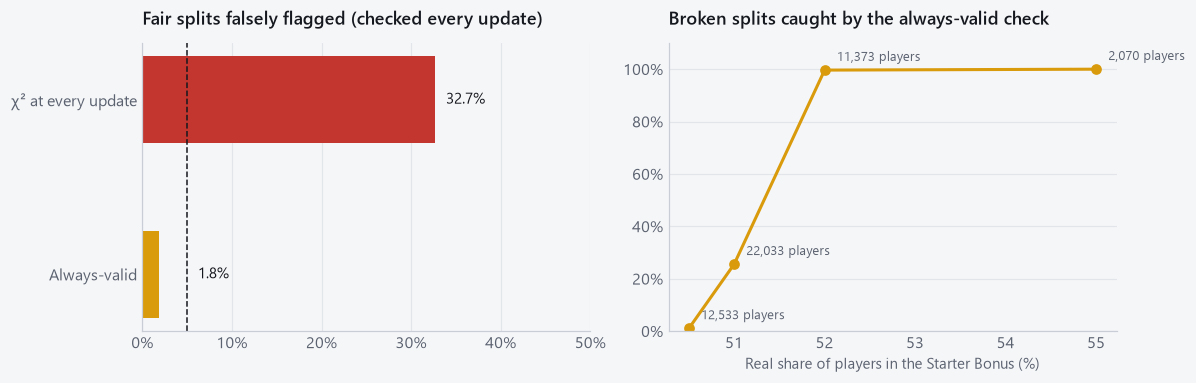

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
vals = srm_null.xs("alpha = 0.05", level=1)
axes[0].barh(vals.index[::-1], vals.rate[::-1], color=[TREAT, STOP], height=0.5)
for y, v in enumerate(vals.rate[::-1]):
    axes[0].text(max(v, 0.05) + 0.012, y, f"{v:.1%}", va="center", fontsize=10)
axes[0].axvline(0.05, color=INK, ls="--", lw=1)
axes[0].xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_xlim(0, max(0.5, vals.ci_high.max() + 0.08))
axes[0].grid(axis="y", visible=False)
axes[0].grid(axis="x")
axes[0].set_title("Fair splits falsely flagged (checked every update)")
sp = srm_power.reset_index()
axes[1].plot(sp["treatment share"] * 100, sp["caught by 30,000"], color=TREAT, marker="o")
for _, r in sp.iterrows():
    if np.isfinite(r["median players when caught"]):
        axes[1].annotate(f"{r['median players when caught']:,.0f} players", (r["treatment share"] * 100, r["caught by 30,000"]),
                         textcoords="offset points", xytext=(8, 6), ha="left", fontsize=8.5, color=MUTED)
axes[1].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[1].set_ylim(0, 1.1)
axes[1].set_xlabel("Real share of players in the Starter Bonus (%)")
axes[1].set_title("Broken splits caught by the always-valid check")
fig.tight_layout()
savefig(fig, "05_split_check")

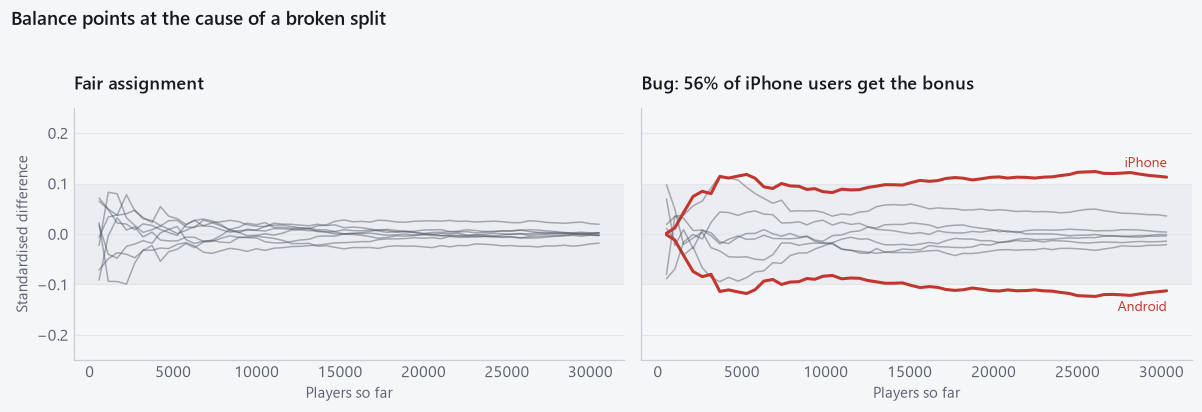

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, df_, title in [(axes[0], fair, "Fair assignment"), (axes[1], bug, "Bug: 56% of iPhone users get the bonus")]:
    ax.axhspan(-0.1, 0.1, color="#e2e5ea", alpha=0.5, lw=0)
    for col in df_.columns:
        hot = col in ("iPhone", "Android") and title.startswith("Bug")
        ax.plot(df_.index, df_[col], color=STOP if hot else CONTROL, lw=2 if hot else 1, alpha=1 if hot else 0.45)
    ax.set_ylim(-0.25, 0.25)
    ax.set_xlabel("Players so far")
    ax.set_title(title)
axes[0].set_ylabel("Standardised difference")
axes[1].text(bug.index[-1], bug["iPhone"].iloc[-1] + 0.02, "iPhone", ha="right", color=STOP, fontsize=9)
axes[1].text(bug.index[-1], bug["Android"].iloc[-1] - 0.04, "Android", ha="right", color=STOP, fontsize=9)
fig.suptitle("Balance points at the cause of a broken split", x=0.01, ha="left", fontweight="semibold", y=1.03)
fig.tight_layout()
savefig(fig, "05_balance_bug")

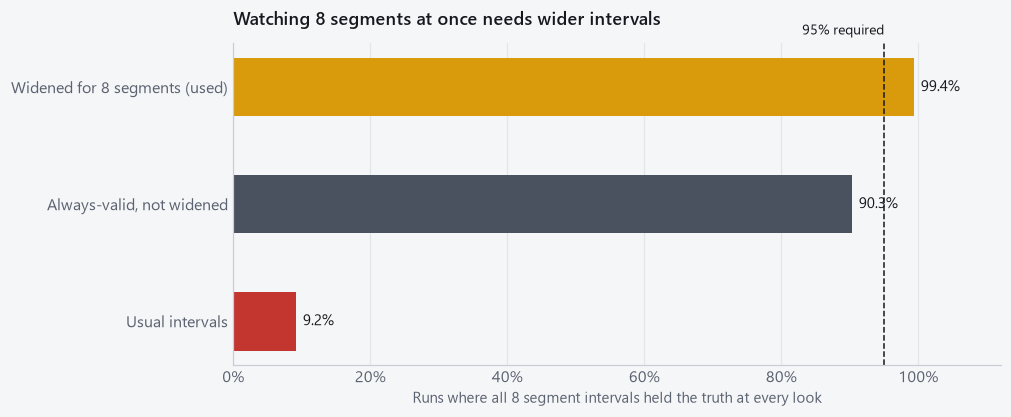

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.8))
labels = list(fw.index)
ax.barh(labels[::-1], fw.rate[::-1], color=[STOP, CONTROL, TREAT], height=0.5)
for y, v in enumerate(fw.rate[::-1]):
    ax.text(v + 0.01, y, f"{v:.1%}", va="center", fontsize=10)
ax.axvline(0.95, color=INK, ls="--", lw=1)
ax.text(0.95, 2.45, "95% required", ha="right", fontsize=9)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(0, 1.12)
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_xlabel("Runs where all 8 segment intervals held the truth at every look")
ax.set_title("Watching 8 segments at once needs wider intervals")
savefig(fig, "05_segment_coverage")

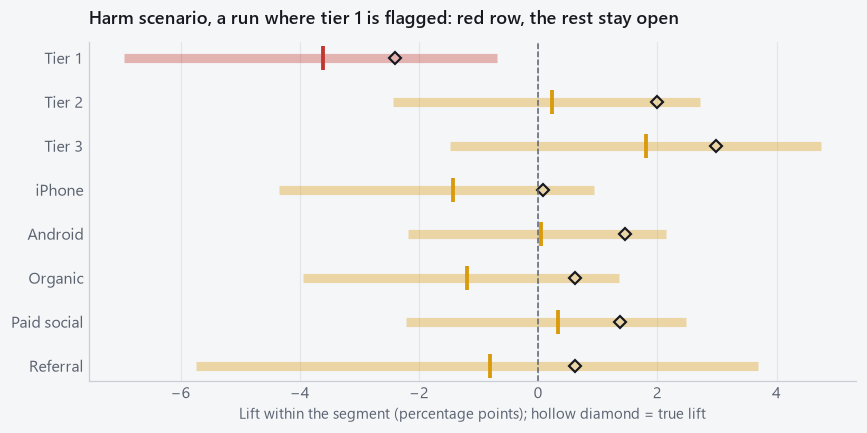

In [14]:
# One harm-scenario run, at the end: the rows the page will show.
r0 = int(np.argmax(flagged_t1))
last = -1
fig, ax = plt.subplots(figsize=(9, 4))
ys = np.arange(K)[::-1]
for j, y in zip(range(K), ys):
    lo, hi, d = harm["lo"][r0, last, j], harm["hi"][r0, last, j], harm["d"][r0, last, j]
    color = STOP if hi < 0 else TREAT
    ax.hlines(y, lo * 100, hi * 100, color=color, lw=6, alpha=0.35)
    ax.plot([d * 100], [y], "|", color=color, ms=16, mew=2.5)
    ax.plot([truth_harm[j] * 100], [y], "D", ms=6, mfc="none", mec=INK, mew=1.4)
ax.axvline(0, color=MUTED, ls="--", lw=1)
ax.set_yticks(ys, [f"{lvl}" for _, lvl, _ in SEGMENTS])
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_xlabel("Lift within the segment (percentage points); hollow diamond = true lift")
ax.set_title("Harm scenario, a run where tier 1 is flagged: red row, the rest stay open")
savefig(fig, "05_segment_rows_harm")

## 6. Results

In [15]:
av05 = srm_null.loc[("Always-valid", "alpha = 0.05")]
chi05 = srm_null.loc[("χ² at every update", "alpha = 0.05")]
print(f"Split check, fair splits flagged (alpha 0.05): always-valid {av05.rate:.2%}, χ² {chi05.rate:.1%}")
print(f"Segments, familywise coverage: widened {fw.loc['Widened for 8 segments (used)', 'rate']:.1%}, "
      f"not widened {fw.loc['Always-valid, not widened', 'rate']:.1%}, usual {fw.loc['Usual intervals', 'rate']:.1%}")
print(f"Harm scenario: tier 1 flagged in {flagged_t1.mean():.1%} of runs; any unharmed segment flagged in {false_other.mean():.1%}")

Split check, fair splits flagged (alpha 0.05): always-valid 1.85%, χ² 32.7%
Segments, familywise coverage: widened 99.4%, not widened 90.3%, usual 9.2%
Harm scenario: tier 1 flagged in 21.2% of runs; any unharmed segment flagged in 0.1%


- **The split check can be watched.** Checked at every update, the χ² flags many perfectly fair splits; the always-valid check stays within its error rate. At the page's threshold (p < 0.001) it still catches a 52/48 split in most runs and a 55/45 split almost immediately.
- **Balance says where it broke.** Under the iPhone bug, the overall split drifts (the split check fires) and the iPhone/Android rows of the balance table stand out, while the others stay near zero.
- **Eight segments need wider intervals.** Watching eight segments at every look with unwidened intervals lets at least one miss its truth too often; widening each to α/8 restores the 95% guarantee for all of them together.
- **The harm check is trustworthy but underpowered.** When the bonus backfires in tier 1 (true lift −2.4 points) while helping overall, tier 1 is flagged in only about one run in five by 30,000 players, while unharmed segments are almost never flagged (0.1%). A red flag can be believed; the absence of one is not evidence of no harm. Tier 1 holds about 9,000 players at the maximum and each interval is widened eight ways, so only large harms show up. A one-sided check (harm only runs one way) would lift detection to roughly a quarter in a quick approximation, not enough to change the conclusion, and would need a proper one-sided boundary.
- **What this means for the page.** The segment rows say "no group shows clear harm yet; this check only catches large harms", never "no group is harmed". Guarding the business against harm is the job of the overall guardrail (net revenue per player, notebook 06), which uses all players.
- Segments are for spotting harm, not for picking winners; targeting is the job of the article in M10.

## 7. What gets promoted

| Function | Goes to | Guarded by |
|---|---|---|
| `srm_log_bf`, `srm_always_valid_p` (vectorised) | `ablab/checks.py` (already there, scalar; vectorised version added) | `tests/test_power_and_checks.py` (matches savvi) |
| `segment_intervals` | `ablab/segments.py`: per-segment always-valid intervals at α/K, tuned to each segment's share | `tests/test_segments.py`; `validity/segments.py` writes familywise coverage and harm detection to `results/segments.json` |
| Segment rows and the harm flag | TS port in `web/src/lib/engine/segments.ts`, shown under "Is any group being harmed?" | fixtures + parity tests |

## 8. Production parity

Segment levels and the widened interval now live in `ablab/segments.py` (TS: `segments.ts`); the vectorised split check matches `ablab.checks`; `validity/segments.py` re-runs coverage and harm detection.

In [16]:
from ablab import segments as prod  # noqa: E402

prod_levels = prod.levels(CFG)
assert [lvl for _, lvl, _ in prod_levels] == [lvl for _, lvl, _ in SEGMENTS]
assert np.allclose([s for _, _, s in prod_levels], seg_share, atol=0.01)  # config shares vs simulated population
r_, k_ = 0, LOOKS - 1
tot = {key: small[key][r_, k_] @ member for key in ("s_t", "n_t", "s_c", "n_c")}
p_t, p_c = tot["s_t"] / tot["n_t"], tot["s_c"] / tot["n_c"]
se_nb = np.sqrt(p_t * (1 - p_t) / tot["n_t"] + p_c * (1 - p_c) / tot["n_c"])
half_nb = se_nb * cs_multiplier(tot["n_t"] + tot["n_c"], rho2_for(PLAN["n_star"] * seg_share, ALPHA / K), ALPHA / K)
lo_p, hi_p = prod.segment_interval(tot["s_t"], tot["n_t"], tot["s_c"], tot["n_c"], seg_share, K, ALPHA, PLAN["n_star"])
assert np.allclose(lo_p, p_t - p_c - half_nb) and np.allclose(hi_p, p_t - p_c + half_nb)
print("ablab.segments reproduces this notebook (levels, shares, widened intervals)")

ablab.segments reproduces this notebook (levels, shares, widened intervals)


## Further reading

Checks that keep a running test trustworthy: the split, balance, and harm in segments. Where to find them: **[local]** = `docs/papers/` in this project (kept out of the repo) · **[Vega: folder]** = `Vega/paper-library/pdfs/<folder>/` (Vega's library also has text versions in `paper-library/md/` and notes in `paper-library/papers/`) · **[airline library: folder]** = `Projects/airline-experimentation/paper-library/pdfs/<folder>/` (a copy of Vega's library plus airline-related extras) · **[online]** = not in any library yet. ★ = read first.

Theory notes in this project: [anytime-valid](../docs/theory/anytime-valid.md), [balancing](../docs/theory/balancing.md).

- ★ Fabijan, A., Gupchup, J., Gupta, S., Omhover, J., Qin, W., Vermeer, L., & Dmitriev, P. (2019). Diagnosing sample ratio mismatch in online controlled experiments: a taxonomy and rules of thumb for practitioners. *KDD 2019*. What causes a broken split. **[online]** https://doi.org/10.1145/3292500.3330722
- ★ Lindon, M., & Malek, A. (2022). Anytime-valid inference for multinomial count data. *NeurIPS 2022*. The always-valid split check used here. **[online]** https://arxiv.org/abs/2011.03567
- Nie, K., Zhang, Z., et al. (2022). Ensure A/B test quality at scale with automated randomization validation and sample ratio mismatch detection. *CIKM 2022* (eBay). Sequential split checks in production. **[Vega: 05-power-and-decisions]**
- Schultzberg, M., Ankargren, S., & Frånberg, M. (2024). Risk-aware product decisions in A/B tests with multiple metrics. arXiv:2402.11609. Guardrails and corrections when many metrics are watched. **[Vega: 05-power-and-decisions]**
- Schultzberg, M. *Are Optimal Multiple Testing Corrections Optimal for You?* (Confidence blog). Why Bonferroni-style widening is often the right call. **[Vega: 05-power-and-decisions]**
- Austin, P. C. (2009). Balance diagnostics for comparing the distribution of baseline covariates between treatment groups in propensity-score matched samples. *Statistics in Medicine* 28(25). The standardised-difference rule of thumb. **[online]** https://doi.org/10.1002/sim.3697
- Orellana, S. *Rerandomization, Outcome-Guided Balance, and When It Really Matters* (Medium). What to do when the groups come out unbalanced. **[airline library: 14-airline-related-topics]**
- Imbens, G. W. (2014). Matching methods in practice. Balance measures from the causal-inference side. **[Vega: 00-foundational]**